# ЛР 07. Категориальные признаки в задаче оценки цены автомобиля

Сравниваем способы кодирования на одних и тех же данных. Основная метрика — **MAE в евро**: средний модуль ошибки. Чем меньше MAE, тем лучше.

## 1. Загрузка и разбиение данных

Используем те же признаки и то же разбиение, что в ЛР 06: 60% для обучения, 20% для сравнения вариантов и 20% для итоговой проверки. До разбиения ничего не кодируем и не масштабируем.

In [1]:
# Если библиотек нет, раскомментируйте строку и перезапустите ядро.
# %pip install "scikit-learn>=1.4" pandas numpy scipy matplotlib lightgbm catboost
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
data_path = Path('cars_processed.csv')
if data_path.exists():
    df = pd.read_csv(data_path)
else:
    df = pd.read_csv(
        'https://raw.githubusercontent.com/MVRonkin/BasicDataAnalysisCourse/'
        'refs/heads/main/Workshops/cars_processed.csv'
    )

In [3]:
df = df.rename(columns={'Price(euro)': 'Price', 'Engine_capacity(cm3)': 'Engine'})
df = df.loc[:, ~df.columns.str.startswith('Unnamed:')].reset_index(drop=True)
print(df.shape)
display(df.head())

(32067, 11)


,Make,Model,Year,Style,Distance,Engine,Fuel_type,AutoTransmission,Price,Age,km_year
0,Toyota,Prius,2011,Hatchback,195000.0,1800.0,Hybrid,True,7750.0,11,17727.272727
1,Renault,Grand Scenic,2014,Universal,135000.0,1500.0,Diesel,False,8550.0,8,16875.000000
2,Renault,Laguna,2012,Universal,110000.0,1500.0,Diesel,False,6550.0,10,11000.000000
3,Opel,Astra,2006,Universal,200000.0,1600.0,Metan/Propan,False,4100.0,16,12500.000000
4,Mercedes,Vito,2000,Microvan,300000.0,2200.0,Diesel,False,3490.0,22,13636.363636


In [4]:
y = df['Price']
X = df.drop(columns=['Price', 'Age'])

from sklearn.model_selection import train_test_split

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.4, random_state=42
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, random_state=43
)
print('Train, validation, test:', len(X_train), len(X_valid), len(X_test))

Train, validation, test: 19240 6413 6414


`Age` исключаем как дубликат информации из `Year`. Типы признаков определяем по обучающей выборке.

In [5]:
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
print('Числовые:', num_cols)
print('Текстовые:', cat_cols)
print('Тип AutoTransmission:', X_train['AutoTransmission'].dtype)

Числовые: ['Year', 'Distance', 'Engine', 'km_year']
Текстовые: ['Make', 'Model', 'Style', 'Fuel_type']
Тип AutoTransmission: bool


## 2. Кодируем тип трансмиссии: 1 — автоматическая, 0 — механическая

Применяем один и тот же словарь ко всем частям. Исходный столбец `AutoTransmission` содержит `True` и `False`. Новый столбец с текстовыми названиями не нужен.

In [6]:
auto_map = {True: 1, False: 0}
X_train['AutoTransmission'] = X_train['AutoTransmission'].map(auto_map)
X_valid['AutoTransmission'] = X_valid['AutoTransmission'].map(auto_map)
X_test['AutoTransmission'] = X_test['AutoTransmission'].map(auto_map)

display(X_train['AutoTransmission'].value_counts().sort_index())

AutoTransmission
0    10443
1     8797
Name: count, dtype: int64

### LR и RF с типом трансмиссии и без него

Для каждого алгоритма меняем только набор признаков. Сравниваем MAE и RMSE на validation, обе метрики в евро.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

num_auto_cols = num_cols + ['AutoTransmission']
baseline_rows = []

In [8]:
for cols, label in [(num_cols, 'Без типа трансмиссии'), (num_auto_cols, 'С типом трансмиссии')]:
    lr = LinearRegression()
    lr.fit(X_train[cols], y_train)
    pred = lr.predict(X_valid[cols])
    baseline_rows.append(['LR', label, mean_absolute_error(y_valid, pred),
                          root_mean_squared_error(y_valid, pred)])

In [9]:
rf_params = dict(n_estimators=80, max_depth=16, random_state=42, n_jobs=2)
for cols, label in [(num_cols, 'Без типа трансмиссии'), (num_auto_cols, 'С типом трансмиссии')]:
    rf = RandomForestRegressor(**rf_params)
    rf.fit(X_train[cols], y_train)
    pred = rf.predict(X_valid[cols])
    baseline_rows.append(['RF', label, mean_absolute_error(y_valid, pred),
                          root_mean_squared_error(y_valid, pred)])

In [10]:
baseline = pd.DataFrame(baseline_rows, columns=['Модель', 'Признаки', 'MAE', 'RMSE'])
baseline = baseline.pivot(index='Модель', columns='Признаки', values=['MAE', 'RMSE'])
for metric in ['MAE', 'RMSE']:
    baseline[metric, 'Снижение'] = (
        baseline[metric, 'Без типа трансмиссии'] - baseline[metric, 'С типом трансмиссии']
    )
baseline = baseline.reindex(columns=pd.MultiIndex.from_product([
    ['MAE', 'RMSE'], ['Без типа трансмиссии', 'С типом трансмиссии', 'Снижение']
]))
display(baseline.round(2))

MAE                      ...                RMSE         
       Без типа трансмиссии С типом трансмиссии  ... С типом трансмиссии Снижение
Модель                                           ...                             
LR                  4307.77             4177.20  ...             7584.74   100.41
RF                  2723.71             2673.84  ...             5865.21    22.02

[2 rows x 6 columns]

На validation добавление типа трансмиссии уменьшило MAE на 131 евро для LR и на 50 евро для RF.

**Задание.** Сравните MAE и RMSE с типом трансмиссии и без него. Положительное значение в столбце «Снижение» означает, что ошибка уменьшилась.

### Дерево глубины 3 с типом трансмиссии

Используем числа и `AutoTransmission`. Разбиение `AutoTransmission ≤ 0.5` отделяет механическую трансмиссию (0) от автоматической (1). На этом дереве такое разбиение есть.

In [11]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

tree = DecisionTreeRegressor(max_depth=3, random_state=42)
tree.fit(X_train[num_auto_cols], y_train)
tree_pred = tree.predict(X_valid[num_auto_cols])
print(f'MAE дерева на validation: {mean_absolute_error(y_valid, tree_pred):.2f} €')

MAE дерева на validation: 3527.34 €


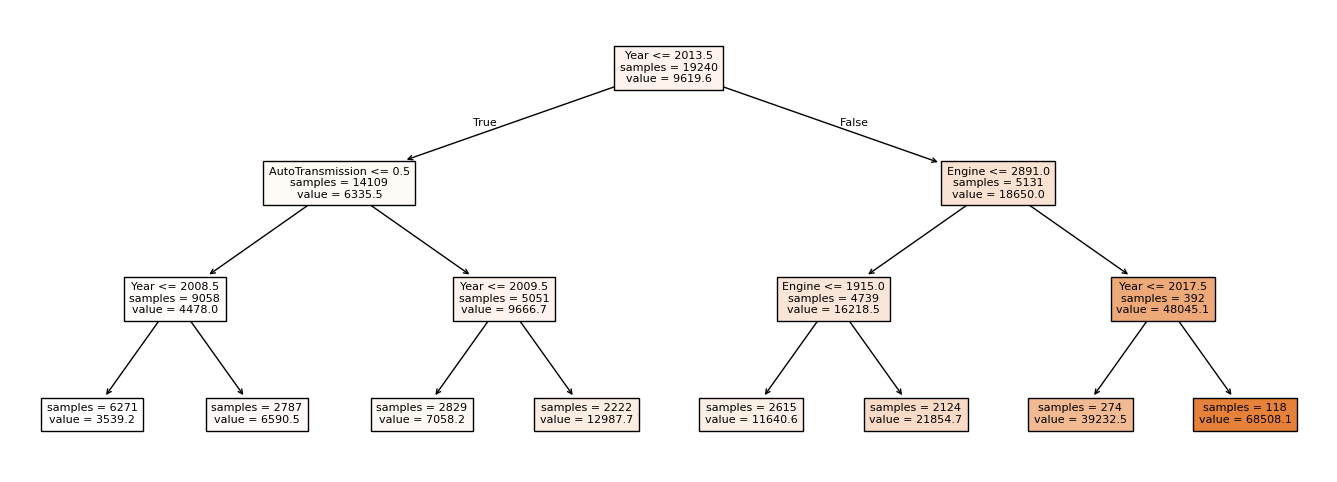

In [12]:
plt.figure(figsize=(17, 6))
plot_tree(tree, feature_names=num_auto_cols, filled=True,
          impurity=False, precision=1, fontsize=8)
plt.show()

## 3. RF: целочисленное кодирование текстовых признаков

Каждому названию можно назначить целый код. Дерево использует условия вида `код ≤ порог`: значение кода влияет на то, какие категории попадут в одну ветвь. Это произвольный порядок, поэтому результат может зависеть от нумерации.

Кодируем все значения в каждом текстовом столбце. Словари строим по train. Категории, которых в train не было, получают код −1.

In [13]:
def encode_for_rf(train, other, threshold):
    train_enc = train.copy()
    other_enc = other.copy()
    for col in cat_cols:
        freq = train[col].value_counts(normalize=True)
        cutoff = threshold if col == 'Model' else 0
        kept = sorted(freq[freq >= cutoff].index)
        codes = {name: i for i, name in enumerate(kept)}
        train_enc[col] = train[col].map(codes).fillna(-1).astype(int)
        other_enc[col] = other[col].map(codes).fillna(-1).astype(int)
    return train_enc, other_enc

In [14]:
train_all, valid_all = encode_for_rf(X_train, X_valid, threshold=0)
rf_all = RandomForestRegressor(**rf_params)
rf_all.fit(train_all, y_train)
pred_rf_all_valid = rf_all.predict(valid_all)
mae_rf_all = mean_absolute_error(y_valid, pred_rf_all_valid)
rmse_rf_all = root_mean_squared_error(y_valid, pred_rf_all_valid)
mae_rf_num = baseline.loc['RF', ('MAE', 'С типом трансмиссии')]
print(f'RF, числа и тип трансмиссии — MAE: {mae_rf_num:.2f} €')
print(f'RF, все признаки — MAE: {mae_rf_all:.2f} €')

RF, числа и тип трансмиссии — MAE: 2673.84 €
RF, все признаки — MAE: 2023.35 €


### Редкие категории в столбце `Model`

Для каждой модели считаем долю записей на train: число записей с этой моделью делим на число записей с указанной моделью. При пороге 0,5% редкими считаем модели с долей **строго меньше 0,5%**.

Проверяем пороги **0,1%, 0,5%, 1%, 1,5% и 2%** только для `Model`. В других признаках известные категории сохраняем отдельно. Доля записей в группе редких — результат объединения, а не порог.

In [15]:
model_counts = X_train['Model'].value_counts()
model_freq = model_counts / model_counts.sum()
model_stats = pd.DataFrame({
    'Записей на train': model_counts,
    'Доля записей на train, %': 100 * model_freq
})
display(pd.concat([model_stats.head(5), model_stats.tail(5)]).round(3))

,Записей на train,"Доля записей на train, %"
Model,,
E Class,669,3.477
5 Series,614,3.191
Passat,511,2.656
Megane,489,2.542
Golf,470,2.443
500L,1,0.005
Logo,1,0.005
Envision,1,0.005
C30,1,0.005


In [16]:
rows = []
for threshold_pct in [0.1, 0.5, 1, 1.5, 2]:
    rare = model_freq < threshold_pct / 100
    rows.append([threshold_pct, rare.sum(), 100 * model_freq[rare].sum()])

rare_counts = pd.DataFrame(rows, columns=[
    'Порог для Model, %', 'Редких категорий', 'Записей в группе редких, %'
])
display(rare_counts.set_index('Порог для Model, %').round(2))

,Редких категорий,"Записей в группе редких, %"
"Порог для Model, %",,
0.1,553,16.12
0.5,674,42.66
1.0,701,61.75
1.5,712,75.01
2.0,717,83.34


### Что меняется при объединении редких моделей

Редкие категории `Model` объединяем в группу с кодом `−1`. Неизвестные категории на validation и test тоже получают `−1`. Доли для определения редких моделей считаем только на train.

Сравниваем шесть вариантов RF с одинаковыми параметрами: без объединения, с порогом 0,1%, 0,5%, 1%, 1,5% и 2%.

In [17]:
rare_rows = [[0, train_all['Model'].nunique(), mae_rf_all]]
for threshold_pct in [0.1, 0.5, 1, 1.5, 2]:
    train_enc, valid_enc = encode_for_rf(X_train, X_valid, threshold_pct / 100)
    rf = RandomForestRegressor(**rf_params)
    rf.fit(train_enc, y_train)
    mae = mean_absolute_error(y_valid, rf.predict(valid_enc))
    rare_rows.append([threshold_pct, train_enc['Model'].nunique(), mae])

rare_results = pd.DataFrame(rare_rows, columns=[
    'Порог для Model, %', 'Категорий Model после объединения', 'MAE, евро'
])
display(rare_results.set_index('Порог для Model, %').round(2))

,Категорий Model после объединения,"MAE, евро"
"Порог для Model, %",,
0.0,723,2023.35
0.1,171,2034.17
0.5,50,2096.78
1.0,23,2109.96
1.5,12,2129.98
2.0,7,2138.25


Нулевой порог означает, что известные категории Model не объединяются. При пороге 0,1% число категорий Model сократилось с 723 до 171, а MAE на validation выросла с 2 023,35 до 2 034,17 евро. Это наименьший рост ошибки среди проверенных порогов.

**Задание.** Сравните MAE и число категорий Model без объединения и при каждом пороге. Какой порог дал наименьшую MAE на validation?

### Важность признаков в RF

`feature_importances_` показывает вклад признаков в уменьшение квадратичной ошибки при разбиениях, усреднённый по деревьям леса. Чем больше значение, тем чаще или сильнее признак уменьшал ошибку при разбиениях.

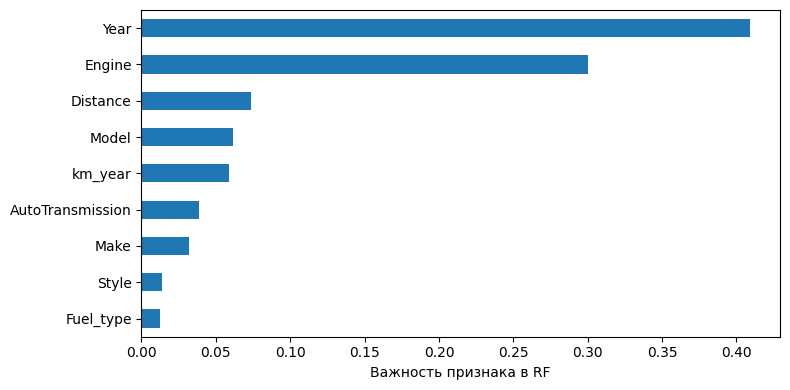

In [18]:
importance = pd.Series(rf_all.feature_importances_, index=train_all.columns)
importance = importance.sort_values(ascending=False)
importance.iloc[::-1].plot.barh(figsize=(8, 4), xlabel='Важность признака в RF')
plt.tight_layout()
plt.show()

### Сокращение набора признаков RF

Убираем от одного до трёх признаков с наименьшей важностью. На validation выбираем самый короткий набор, у которого и MAE, и RMSE выросли не более чем на 2% относительно полного набора. Это учебный допуск. Test при выборе не используем.

In [19]:
cut_rows = [[0, mae_rf_all, rmse_rf_all]]
rf_reduced, reduced_cols = rf_all, train_all.columns.tolist()
for drop_count in [1, 2, 3]:
    cols = importance.index[:-drop_count].tolist()
    rf_candidate = RandomForestRegressor(**rf_params)
    rf_candidate.fit(train_all[cols], y_train)
    pred = rf_candidate.predict(valid_all[cols])
    mae = mean_absolute_error(y_valid, pred)
    rmse = root_mean_squared_error(y_valid, pred)
    cut_rows.append([drop_count, mae, rmse])
    if mae <= 1.02 * mae_rf_all and rmse <= 1.02 * rmse_rf_all:
        rf_reduced, reduced_cols = rf_candidate, cols

In [20]:
cut_results = pd.DataFrame(cut_rows, columns=['Убрано признаков', 'MAE, евро', 'RMSE, евро'])
cut_results['Изменение MAE, %'] = 100 * (cut_results['MAE, евро'] / mae_rf_all - 1)
cut_results['Изменение RMSE, %'] = 100 * (cut_results['RMSE, евро'] / rmse_rf_all - 1)
display(cut_results.set_index('Убрано признаков').round(2))
print('Исключены:', train_all.columns.difference(reduced_cols).tolist())

Исключены: ['Fuel_type']


,"MAE, евро","RMSE, евро","Изменение MAE, %","Изменение RMSE, %"
Убрано признаков,,,,
0,2023.35,5162.30,0.00,0.00
1,2055.67,5205.47,1.60,0.84
2,2067.80,5222.88,2.20,1.17
3,2147.24,5298.31,6.12,2.63


В этом разбиении выбран набор без `Fuel_type`. При удалении этого признака рост обеих метрик на validation укладывается в 2%. Результат на test проверим отдельно.

## 4. LR: One-Hot Encoding

Если передать марку как число, LR умножит её код на один коэффициент. Тогда переход от кода 1 к 2 изменит прогноз на ту же величину, что переход от 2 к 3. Для названий марок такое ограничение не обосновано.

One-Hot Encoding (OHE) создаёт отдельный индикатор для каждой категории. Тип трансмиссии уже задан одним индикатором 0/1.

Столбцы для validation и test выравниваем по именам столбцов train. Неизвестная категория не получает отдельного столбца: все её индикаторы из train равны нулю.

In [21]:
train_ohe = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
valid_ohe = pd.get_dummies(X_valid, columns=cat_cols, dtype=int)
test_ohe = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

valid_ohe = valid_ohe.reindex(columns=train_ohe.columns, fill_value=0)
test_ohe = test_ohe.reindex(columns=train_ohe.columns, fill_value=0)

print(f'Столбцов до OHE: {X_train.shape[1]} | После OHE: {train_ohe.shape[1]}')
display(pd.DataFrame({'До OHE': X_train.dtypes.index, 'Тип': X_train.dtypes.astype(str).values}))
display(train_ohe.iloc[:5, :12])

Столбцов до OHE: 9 | После OHE: 768


,До OHE,Тип
0,Make,object
1,Model,object
2,Year,int64
3,Style,object
4,Distance,float64
5,Engine,float64
6,Fuel_type,object
7,AutoTransmission,int64
8,km_year,float64


,Year,Distance,Engine,AutoTransmission,km_year,Make_Audi,Make_BMW,Make_Chevrolet,Make_Dacia,Make_Ford,Make_Honda,Make_Hyundai
22222,2007,187000.0,1400.0,1,12466.666667,0,0,0,0,0,0,0
3091,2014,30500.0,2000.0,1,3812.500000,0,0,0,0,0,0,0
24316,2009,244140.0,2200.0,0,18780.000000,0,0,0,0,0,0,0
22327,1992,248600.0,1998.0,0,8286.666667,0,0,0,0,0,0,0
13572,2018,109000.0,2000.0,1,27250.000000,0,0,0,0,0,0,0


In [22]:
lr_ohe = LinearRegression()
lr_ohe.fit(train_ohe, y_train)
pred_ohe_valid = lr_ohe.predict(valid_ohe)
mae_ohe = mean_absolute_error(y_valid, pred_ohe_valid)
rmse_ohe = root_mean_squared_error(y_valid, pred_ohe_valid)
mae_lr_num = baseline.loc['LR', ('MAE', 'С типом трансмиссии')]
rmse_lr_num = baseline.loc['LR', ('RMSE', 'С типом трансмиссии')]
print(f'LR с типом трансмиссии — MAE: {mae_lr_num:.2f} €, RMSE: {rmse_lr_num:.2f} €')
print(f'LR с OHE — MAE: {mae_ohe:.2f} €, RMSE: {rmse_ohe:.2f} €')

LR с типом трансмиссии — MAE: 4177.20 €, RMSE: 7584.74 €
LR с OHE — MAE: 3174.79 €, RMSE: 6496.48 €


### Почему рост числа столбцов важен

После OHE у модели больше коэффициентов и больше данных для хранения. У редкой категории может быть свой коэффициент, оцененный по нескольким записям. Такая оценка нестабильна. Следующий способ кодирования оставляет по одному столбцу на признак.

## 5. LR: Target Encoding

Категорию заменяем сглаженной оценкой средней цены для этой категории. Для обучающей строки оценка вычисляется по другим строкам: её собственная цена не должна попасть в её признаки. `TargetEncoder.fit_transform()` делает это по внутренним разбиениям. Для validation и test используем только `transform()`.

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder

te = ColumnTransformer([
    ('cat', TargetEncoder(target_type='continuous', cv=5, random_state=42), cat_cols),
    ('num', 'passthrough', num_auto_cols)
])
train_te = te.fit_transform(X_train, y_train)
valid_te = te.transform(X_valid)
test_te = te.transform(X_test)

In [24]:
lr_te = LinearRegression()
lr_te.fit(train_te, y_train)
mae_te = mean_absolute_error(y_valid, lr_te.predict(valid_te))
encoding_results = pd.DataFrame({
    'Кодирование': ['OHE', 'Target Encoding'],
    'Столбцов': [train_ohe.shape[1], train_te.shape[1]],
    'MAE на validation': [mae_ohe, mae_te]
})
display(encoding_results.round(2))

,Кодирование,Столбцов,MAE на validation
0,OHE,768,3174.79
1,Target Encoding,9,3575.57


В этом эксперименте Target Encoding уменьшил число столбцов с 768 до 9, но повысил MAE на validation. OHE лучше для LR на этих данных по выбранной метрике.

**Задание.** Во сколько раз уменьшилось число столбцов? Уменьшилась ли MAE? Сокращение числа признаков само по себе не гарантирует улучшения прогноза.

## 6. Бонус. CatBoost и LightGBM

Обучаем по одной модели без подбора параметров. CatBoost получает исходные текстовые категории. LightGBM получает матрицу после OHE, как линейная модель.

In [25]:
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

catboost = CatBoostRegressor(cat_features=cat_cols, verbose=False,
                            random_seed=42, allow_writing_files=False)
catboost.fit(X_train, y_train)
pred_catboost = catboost.predict(X_test)

In [26]:
lightgbm = LGBMRegressor(random_state=42, verbosity=-1, n_jobs=2)
lightgbm.fit(train_ohe.to_numpy(), y_train)
pred_lightgbm = lightgbm.predict(test_ohe.to_numpy())

## 7. Бонус. LR на логарифме цены

Цена положительна и имеет длинный правый хвост. Посмотрим, как меняется распределение при логарифмировании. Близость `log(Price)` к нормальному распределению проверяем по графику, а не предполагаем заранее.

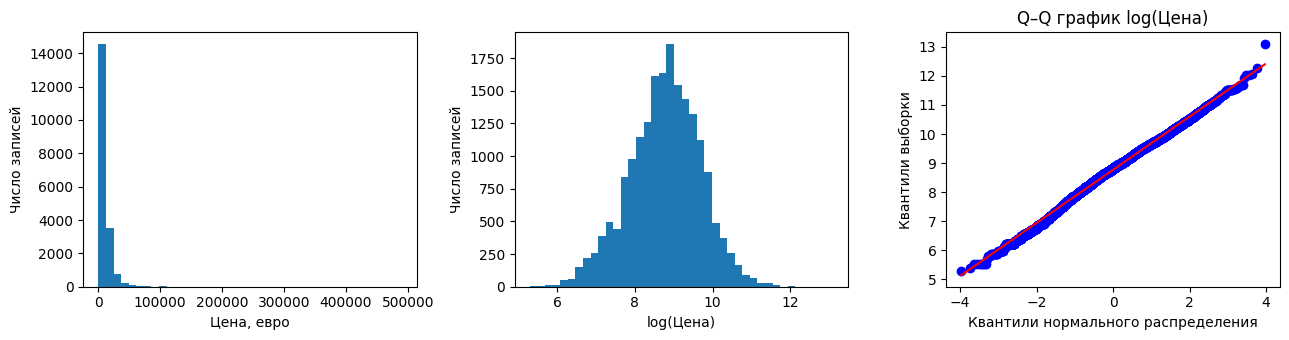

In [27]:
from scipy.stats import probplot

y_train_log = np.log(y_train)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(y_train, bins=40)
axes[0].set(xlabel='Цена, евро', ylabel='Число записей')
axes[1].hist(y_train_log, bins=40)
axes[1].set(xlabel='log(Цена)', ylabel='Число записей')
probplot(y_train_log, dist='norm', plot=axes[2])
axes[2].set(title='Q–Q график log(Цена)', xlabel='Квантили нормального распределения',
            ylabel='Квантили выборки')
fig.tight_layout()
plt.show()

Распределение логарифма цены более симметрично. На Q–Q графике точки близки к прямой, но крайние значения отклоняются от неё.

Обучаем LR на тех же признаках OHE. Меняем только целевую переменную. Перед расчётом ошибки возвращаем прогноз в евро через `exp()`.

In [28]:
lr_log = LinearRegression()
lr_log.fit(train_ohe, y_train_log)
pred_log = lr_log.predict(test_ohe)
pred_price = np.exp(pred_log)

### Итоговая ошибка на test

Сравниваем все прогнозы в евро. MAE показывает средний модуль ошибки. RMSE сильнее реагирует на крупные ошибки. Сопоставляем LR на исходной цене и LR на логарифме на одних и тех же признаках.

In [29]:
_, test_rf = encode_for_rf(X_train, X_test, threshold=0)
test_predictions = {
    'RF: все признаки': rf_all.predict(test_rf),
    'RF: сокращённый набор': rf_reduced.predict(test_rf[reduced_cols]),
    'LR + OHE': lr_ohe.predict(test_ohe),
    'LR + Target Encoding': lr_te.predict(test_te),
    'CatBoost': pred_catboost,
    'LightGBM': pred_lightgbm,
    'LR + OHE + log(Price)': pred_price
}

In [30]:
test_results = pd.DataFrame([
    [name, mean_absolute_error(y_test, pred), root_mean_squared_error(y_test, pred)]
    for name, pred in test_predictions.items()
], columns=['Модель', 'MAE, евро', 'RMSE, евро']).sort_values('MAE, евро')
display(test_results.round(2))

,Модель,"MAE, евро","RMSE, евро"
4,CatBoost,2046.28,5561.20
5,LightGBM,2132.52,5342.05
0,RF: все признаки,2145.26,7747.02
6,LR + OHE + log(Price),2146.27,5949.88
1,RF: сокращённый набор,2185.44,7836.06
2,LR + OHE,3233.42,6859.46
3,LR + Target Encoding,3626.90,7190.51


Сравните изменение MAE и RMSE после обучения LR на логарифме цены. Близкие значения MAE у двух моделей сами по себе не показывают, насколько устойчива разница.

### Как MAE и RMSE зависят от разбиения данных

Объединяем исходные train и validation. Для каждого `random_state` от 0 до 99 делим эти данные заново: 75% на обучение, 25% на проверку. Исходный test в эти повторы не входит.

На каждом новом train строим словари категорий и обучаем два RF: со всеми признаками и с сокращённым набором, выбранным выше. Для обоих RF используем одно и то же разбиение. `random_state` самого леса остаётся равным 42. Боксплоты показывают, как меняются ошибки на validation при смене разбиения. Цикл обучает 200 лесов и может занять несколько минут.

In [31]:
X_dev = pd.concat([X_train, X_valid])
y_dev = pd.concat([y_train, y_valid])
full = 'RF: все признаки'
reduced = 'RF: сокращённый набор'
feature_sets = {full: X_dev.columns.tolist(), reduced: reduced_cols}
split_rows = []

for seed in range(100):
    X_fit, X_eval, y_fit, y_eval = train_test_split(
        X_dev, y_dev, test_size=0.25, random_state=seed
    )
    X_fit, X_eval = encode_for_rf(X_fit, X_eval, threshold=0)
    for name, cols in feature_sets.items():
        model = RandomForestRegressor(**rf_params)
        model.fit(X_fit[cols], y_fit)
        pred = model.predict(X_eval[cols])
        split_rows.append([seed, name, mean_absolute_error(y_eval, pred),
                           root_mean_squared_error(y_eval, pred)])

split_results = pd.DataFrame(split_rows, columns=['random_state', 'Модель', 'MAE', 'RMSE'])
mae_runs = split_results.pivot(index='random_state', columns='Модель', values='MAE')
rmse_runs = split_results.pivot(index='random_state', columns='Модель', values='RMSE')

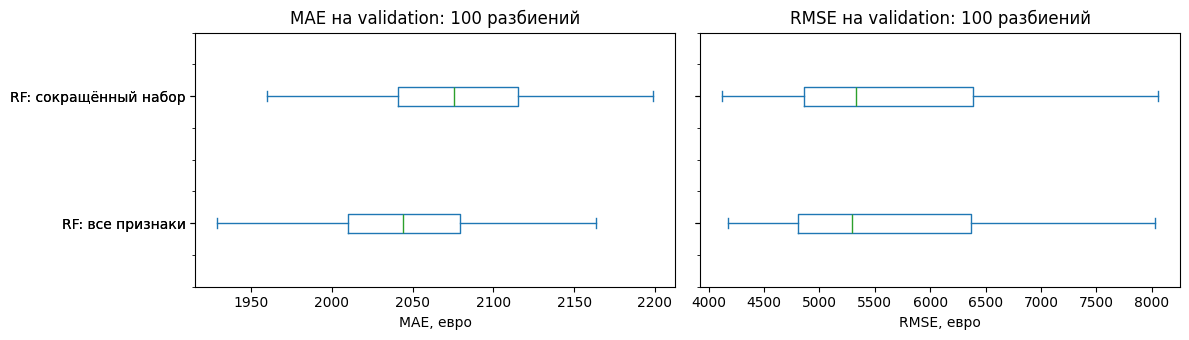

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, runs, name in zip(axes, [mae_runs, rmse_runs], ['MAE', 'RMSE']):
    runs.plot.box(ax=ax, vert=False)
    ax.set(xlabel=f'{name}, евро', title=f'{name} на validation: 100 разбиений')
fig.tight_layout()
plt.show()

### RF: все признаки или сокращённый набор

В каждом повторе вычитаем ошибку полного RF из ошибки сокращённого RF. Положительная разность означает, что сокращённый набор дал большую ошибку на проверочной части этого разбиения.

In [33]:
for label, runs in [('MAE', mae_runs), ('RMSE', rmse_runs)]:
    delta = runs[reduced] - runs[full]
    print(f'{label}: сокращённый RF хуже в {(delta > 0).sum()} из {len(delta)} разбиений')
    print(f'Разность: от {delta.min():.2f} до {delta.max():.2f} евро')

MAE: сокращённый RF хуже в 100 из 100 разбиений
Разность: от 6.25 до 56.02 евро
RMSE: сокращённый RF хуже в 74 из 100 разбиений
Разность: от -214.28 до 469.96 евро


На исходном полном test исключение `Fuel_type` повысило MAE на 40,18 € (+1,9%), а RMSE — на 89,05 € (+1,1%). Это отдельная итоговая проверка; боксплоты выше показывают разброс метрик при повторных разбиениях train + validation.

### Боксплоты абсолютных ошибок на полном test

Здесь каждая запись даёт одну абсолютную ошибку. Линия внутри бокса — медиана, сам бокс охватывает центральные 50% ошибок. Отдельные точки за усами скрыты для читаемости. При расчёте MAE и RMSE используются все ошибки.

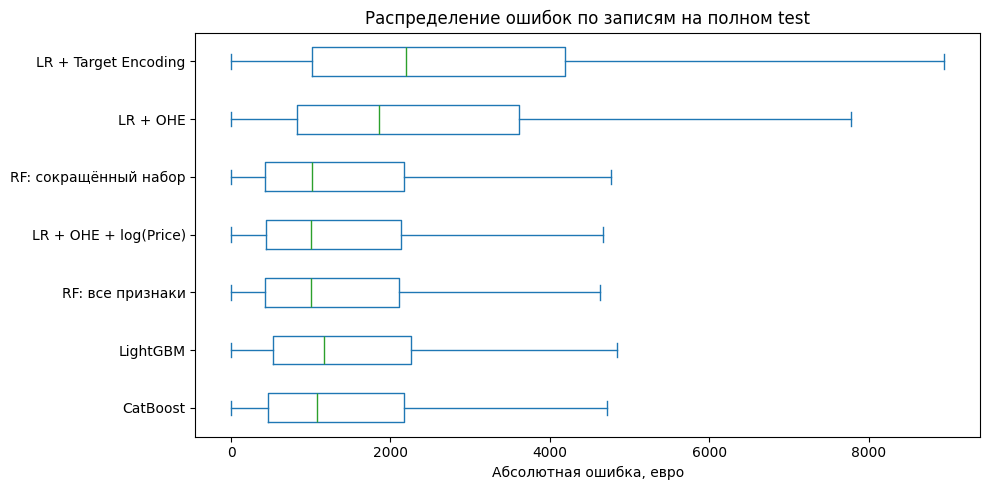

In [34]:
abs_errors = pd.DataFrame({
    name: np.abs(y_test.to_numpy() - pred)
    for name, pred in test_predictions.items()
})[test_results['Модель']]
ax = abs_errors.plot.box(vert=False, showfliers=False, figsize=(10, 5))
ax.set_xlabel('Абсолютная ошибка, евро')
ax.set_title('Распределение ошибок по записям на полном test')
plt.tight_layout()
plt.show()

### Распределение остатков

Регрессия не меняет распределение цен в исходных данных. Отдельно от распределения цели проверим **остатки** — разности между фактическим значением и прогнозом в шкале обучения. На Q–Q графике близость точек к прямой указывает на близость к нормальному распределению. Систематические отклонения, особенно в хвостах, указывают на различия.

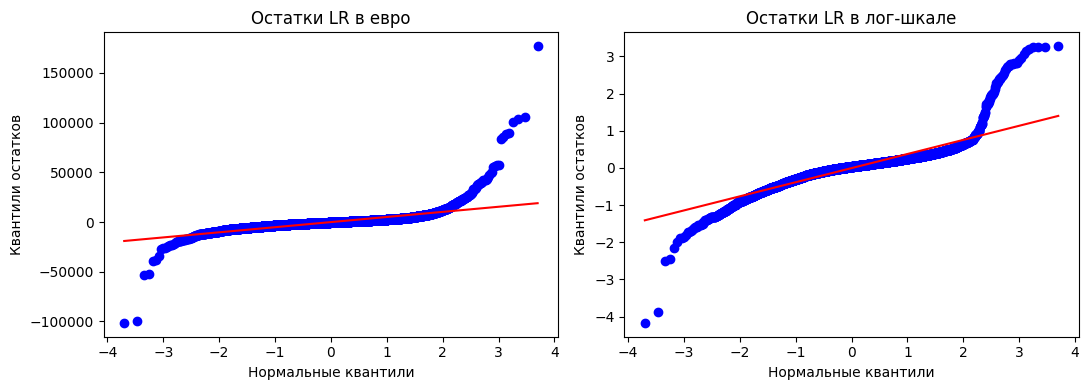

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
probplot(y_test - test_predictions['LR + OHE'], dist='norm', plot=axes[0])
probplot(np.log(y_test) - pred_log, dist='norm', plot=axes[1])
axes[0].set(title='Остатки LR в евро', xlabel='Нормальные квантили', ylabel='Квантили остатков')
axes[1].set(title='Остатки LR в лог-шкале', xlabel='Нормальные квантили', ylabel='Квантили остатков')
fig.tight_layout()
plt.show()

У обеих моделей точки в хвостах заметно отклоняются от прямой. Логарифмирование цены не сделало распределение остатков нормальным.

**Задание.** На сколько евро изменились MAE и RMSE после логарифмирования? Сравните результат с обоими бустингами. На каком Q–Q графике точки ближе к прямой?